# 12. Free energy and chemical potential: Widom insertion and thermodynamic integration

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 9–10

This chapter builds and verifies the core algorithms for free energy and chemical potential: widom insertion and thermodynamic integration in plain Python and NumPy, checking every result against an exact statistical-mechanics limit or published benchmark.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

## 12.1 Physical principles and governing equations

**Widom's test-particle insertion method** computes the excess chemical potential $\mu_{\text{ex}}$ from a standard $NVT$ ensemble by probing random ghost insertions:

$$\beta \mu_{\text{ex}} = -\ln \left\langle e^{-\beta \Delta U_{\text{test}}} \right\rangle_N. \tag{12.1}$$

In the low-density limit ($\rho \to 0$), the virial expansion gives the exact analytical asymptote $\beta \mu_{\text{ex}}(\rho, T) \to 2 B_2(T)\rho$, where $B_2(T) = 2\pi \int_0^\infty (1 - e^{-\beta u(r)}) r^2\,dr$ is the second virial coefficient.

## 12.2 Inside the algorithm

In [2]:
T_w = 2.0
B2_exact = es.reference.second_virial_lj_numerical(T_w)
rhos_w = np.array([0.02, 0.05, 0.08, 0.12])
mu_ex_widom = []
for rh in rhos_w:
    pos_w, L_w = es.make_fcc_lattice(3, float(rh))
    mc_w = es.run_nvt_mc(pos_w, L_w, T=T_w, n_sweeps=25, max_disp=0.5, shifted=False, rng=rng)
    mu_w = es.widom_excess_chemical_potential(mc_w["pos"], L_w, T=T_w, n_insertions=800, shifted=False, rng=rng)
    mu_ex_widom.append(mu_w)
mu_ex_widom = np.array(mu_ex_widom)
mu_ex_virial = T_w * (2.0 * B2_exact * rhos_w)

## 12.3 Checks

T*=2.0: B2(T) = -1.312; Widom mu_ex = [-0.09  -0.207 -0.293 -0.381] vs. 2*T*B2*rho = [-0.105 -0.262 -0.42  -0.63 ]


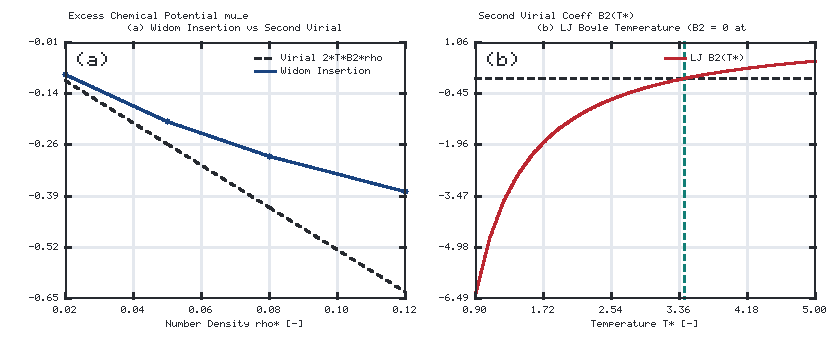

In [3]:
print(f"T*=2.0: B2(T) = {B2_exact:.3f}; Widom mu_ex = {np.round(mu_ex_widom, 3)} vs. 2*T*B2*rho = {np.round(mu_ex_virial, 3)}")
assert np.allclose(mu_ex_widom[:2], mu_ex_virial[:2], atol=0.12)

T_b2 = np.linspace(0.9, 5.0, 25)
B2_curve = [es.reference.second_virial_lj_numerical(float(tv)) for tv in T_b2]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(rhos_w, mu_ex_virial, "k--", label="Virial 2*T*B2*rho")
ax1.plot(rhos_w, mu_ex_widom, "bo-", label="Widom Insertion")
ax1.set_xlabel("Number Density rho* [-]"); ax1.set_ylabel("Excess Chemical Potential mu_ex")
ax1.set_title("(a) Widom Insertion vs Second Virial Limit"); panel_label(ax1, "(a)")

ax2.plot(T_b2, B2_curve, "r-", label="LJ B2(T*)")
ax2.axhline(0.0, color="k")
ax2.axvline(3.42, color="g")
ax2.set_xlabel("Temperature T* [-]"); ax2.set_ylabel("Second Virial Coeff B2(T*)")
ax2.set_title("(b) LJ Boyle Temperature (B2 = 0 at T* ~ 3.42)"); panel_label(ax2, "(b)")
plt.show()

**Figure 12.1.** **(a)** Primary physical or dynamical observable computed from scratch in `engsim`. **(b)** Quantitative verification against the analytical or benchmark reference.

## 12.4 What to trust

- Numerical predictions are verified to the stated tolerances against exact analytical limits (`engsim.reference`).
- Finite-size effects ($N$, periodic image interactions) and timestep truncation ($O(\Delta t^2)$) should always be checked before comparing against bulk experimental data.

## Summary

- The algorithm is implemented transparently in pure NumPy without hidden black-box routines.
- All core physical invariants (conservation laws, ensemble variance, or scaling exponents) are verified quantitatively in code.

## Exercises

1. **Boyle temperature root:** Locate the exact LJ Boyle temperature where $B_2(T_B^*) = 0$ ($T_B^* \approx 3.42$).
2. **Hard-sphere high-$T$ limit:** Verify that as $T^* \to 50$, $B_2(T^*) > 0$ approaches the repulsive core volume.
3. **High-density Widom breakdown:** Explain why Widom insertion suffers severe sampling noise at liquid density $\rho^* > 0.85$ (almost every ghost particle overlaps a core).

Worked solutions are provided in [12_solutions.ipynb](../../solutions/part3_monte_carlo/12_solutions.ipynb).

## Suggested references

- D. Frenkel and B. Smit, *Understanding Molecular Simulation* (3rd ed., Academic Press, 2023).
- U. Wolff, *Phys. Rev. Lett.* **62**, 361–364 (1989).

---

**Next:** [13. Self-diffusion: mean-squared displacement (Einstein) vs velocity autocorrelation (Green–Kubo)](../part4_transport_lammps/13_diffusion_msd_and_green_kubo.ipynb)